# 04 FORCE frozen RF whole curve outage intervention engine

> Saved outputs are from an earlier local run. Portable path edits have **not** been re-executed. See the repository README for setup and scientific limitations.


In [1]:
# نصب کتابخانه‌ها در صورت نیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
from itertools import combinations
import gc
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)

EPSILON = 1e-12
REPLAY_TOLERANCE = 1e-6
NEGATIVE_CONTROL_TOLERANCE = 1e-10

np.random.seed(42)

In [3]:
RUN_MODE = "pilot"  # "pilot" or "full"

PILOT_OUTER_FOLDS = [1]
FULL_OUTER_FOLDS = [1, 2, 3, 4, 5]

ACTIVE_OUTER_FOLDS = (
    PILOT_OUTER_FOLDS
    if RUN_MODE == "pilot"
    else FULL_OUTER_FOLDS
)

# Pilot شامل دو Feature فعال و یک Structural zero-path control است.
PILOT_FEATURES = [
    "GR",
    "RHOB",
    "PEF",
]

# Confirmatory direct/pathway Features + دو Structural controls.
FULL_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP",
]

ACTIVE_FEATURES = (
    PILOT_FEATURES
    if RUN_MODE == "pilot"
    else FULL_FEATURES
)

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()


STAGE_01_DIR = (
    PROJECT_ROOT
    / "01_clean_splits_support"
)

FOLD_ASSIGNMENT_PATH = (
    STAGE_01_DIR
    / "10_grouped_5fold_well_assignment.csv"
)

CAUSAL_CONTRACT_PATH = (
    STAGE_01_DIR
    / "07_causal_project_contract_v0_2_1.json"
)

STAGE_02B_DIR = (
    PROJECT_ROOT
    / "02B_legacy_RF_grouped_well_CV"
    / "full"
)

STAGE_02B_ARTIFACT_DIR = (
    STAGE_02B_DIR
    / "artifacts"
)

STAGE_02B_OOF_DIR = (
    STAGE_02B_DIR
    / "oof_predictions"
)

STAGE_02B_CONFIG_PATH = (
    STAGE_02B_DIR
    / "12_run_configuration.json"
)

STAGE_03_DIR = (
    PROJECT_ROOT
    / "03_nested_grouped_temperature_calibration"
    / "full"
)

STAGE_03_CONFIG_PATH = (
    STAGE_03_DIR
    / "11_run_configuration.json"
)

TEMPERATURE_REGISTRY_PATH = (
    STAGE_03_DIR
    / "10_nested_temperature_registry.json"
)

CALIBRATED_OUTER_OOF_DIR = (
    STAGE_03_DIR
    / "calibrated_outer_oof"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "04_frozen_RF_whole_curve_outage"
)

OUTPUT_DIR = (
    OUTPUT_ROOT
    / RUN_MODE
)

CONDITION_SUMMARY_DIR = (
    OUTPUT_DIR
    / "condition_summaries"
)

ROW_EFFECT_DIR = (
    OUTPUT_DIR
    / "row_effects"
)

PER_WELL_DIR = (
    OUTPUT_DIR
    / "per_well"
)

PER_LITHOLOGY_DIR = (
    OUTPUT_DIR
    / "per_lithology"
)

PLOT_DIR = (
    OUTPUT_DIR
    / "plots"
)

for directory in [
    OUTPUT_ROOT,
    OUTPUT_DIR,
    CONDITION_SUMMARY_DIR,
    ROW_EFFECT_DIR,
    PER_WELL_DIR,
    PER_LITHOLOGY_DIR,
    PLOT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

SAVE_ROW_LEVEL_EFFECTS = True
SKIP_COMPLETED_CONDITIONS = True
PREDICTION_BATCH_SIZE = 100_000

required_paths = [
    TRAIN_PATH,
    FOLD_ASSIGNMENT_PATH,
    STAGE_02B_ARTIFACT_DIR,
    STAGE_02B_OOF_DIR,
    STAGE_02B_CONFIG_PATH,
    STAGE_03_CONFIG_PATH,
    TEMPERATURE_REGISTRY_PATH,
    CALIBRATED_OUTER_OOF_DIR,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Required inputs are missing:\n"
        + "\n".join(missing_paths)
    )

print("RUN_MODE:", RUN_MODE)
print("Outer folds:", ACTIVE_OUTER_FOLDS)
print("Features:", ACTIVE_FEATURES)
print("Output:", OUTPUT_DIR)

RUN_MODE: pilot
Outer folds: [1]
Features: ['GR', 'RHOB', 'PEF']
Output: ${STRATASHIFT_ARTIFACT_ROOT}/04_frozen_RF_whole_curve_outage/pilot


In [4]:
with open(
    STAGE_02B_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_02b_config = json.load(file)

with open(
    STAGE_03_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_03_config = json.load(file)

with open(
    TEMPERATURE_REGISTRY_PATH,
    "r",
    encoding="utf-8",
) as file:
    temperature_registry = json.load(file)

causal_contract = None

if CAUSAL_CONTRACT_PATH.exists():
    with open(
        CAUSAL_CONTRACT_PATH,
        "r",
        encoding="utf-8",
    ) as file:
        causal_contract = json.load(file)

audit_checks = {
    "stage_02b_full": (
        stage_02b_config.get("run_mode")
        == "full"
    ),
    "stage_02b_official_test_unused": (
        stage_02b_config.get(
            "official_test_used",
            True,
        )
        is False
    ),
    "stage_02b_grouped_by_well": (
        stage_02b_config.get(
            "outer_split",
            {},
        ).get("group")
        == "WELL"
    ),
    "stage_02b_legacy_model_unchanged": (
        stage_02b_config.get(
            "legacy_model_unchanged",
            False,
        )
        is True
    ),
    "stage_02b_models_saved": (
        stage_02b_config.get(
            "save_models",
            False,
        )
        is True
    ),
    "stage_02b_preprocessors_saved": (
        stage_02b_config.get(
            "save_preprocessors",
            False,
        )
        is True
    ),
    "stage_03_full": (
        stage_03_config.get("run_mode")
        == "full"
    ),
    "stage_03_official_test_unused": (
        stage_03_config.get(
            "official_test_used",
            True,
        )
        is False
    ),
    "stage_03_strict_nested": (
        stage_03_config.get(
            "nested_calibration",
            {},
        ).get(
            "outer_target_excluded_from_all_inner_model_training",
            False,
        )
        is True
    ),
    "all_five_temperatures_available": (
        sorted(
            int(key)
            for key
            in temperature_registry
        )
        == [1, 2, 3, 4, 5]
    ),
}

failed_audits = [
    name
    for name, passed
    in audit_checks.items()
    if not passed
]

print(
    json.dumps(
        audit_checks,
        indent=2,
    )
)

if failed_audits:
    raise RuntimeError(
        "Input audit failed: "
        + ", ".join(failed_audits)
    )

print("Input-stage audit passed.")

{
  "stage_02b_full": true,
  "stage_02b_official_test_unused": true,
  "stage_02b_grouped_by_well": true,
  "stage_02b_legacy_model_unchanged": true,
  "stage_02b_models_saved": true,
  "stage_02b_preprocessors_saved": true,
  "stage_03_full": true,
  "stage_03_official_test_unused": true,
  "stage_03_strict_nested": true,
  "all_five_temperatures_available": true
}
Input-stage audit passed.


In [5]:
def detect_csv_format(
    file_path,
    num_lines=5,
):
    encodings = [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]

    for encoding in encodings:
        try:
            with open(
                file_path,
                "r",
                encoding=encoding,
            ) as file:
                first_lines = [
                    file.readline()
                    for _ in range(num_lines)
                ]

            if any(
                "," in line
                for line in first_lines
            ):
                delimiter = ","
            elif any(
                ";" in line
                for line in first_lines
            ):
                delimiter = ";"
            elif any(
                "\t" in line
                for line in first_lines
            ):
                delimiter = "\t"
            else:
                delimiter = ","

            return {
                "sep": delimiter,
                "encoding": encoding,
            }

        except UnicodeDecodeError:
            continue

    return {
        "sep": ",",
        "encoding": "utf-8",
    }


csv_format = detect_csv_format(
    TRAIN_PATH
)

train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=csv_format["sep"],
    encoding=csv_format["encoding"],
    low_memory=False,
)

train_raw[
    "ORIGINAL_ROW_ID"
] = np.arange(
    len(train_raw),
    dtype=np.int64,
)

fold_assignment_raw = pd.read_csv(
    FOLD_ASSIGNMENT_PATH
)

well_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if column.upper() == "WELL"
]

fold_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if (
        "FOLD" in column.upper()
        and "SCORE" not in column.upper()
    )
]

if not well_candidates or not fold_candidates:
    raise ValueError(
        "Could not infer WELL/FOLD columns."
    )

fold_assignment = (
    fold_assignment_raw[
        [
            well_candidates[0],
            fold_candidates[0],
        ]
    ]
    .rename(
        columns={
            well_candidates[0]: "WELL",
            fold_candidates[0]: "GROUP_FOLD",
        }
    )
    .drop_duplicates(
        subset=["WELL"]
    )
    .copy()
)

fold_assignment[
    "GROUP_FOLD"
] = pd.to_numeric(
    fold_assignment[
        "GROUP_FOLD"
    ],
    errors="raise",
).astype(int)

well_to_fold = dict(
    zip(
        fold_assignment["WELL"],
        fold_assignment["GROUP_FOLD"],
    )
)

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "WELL"
].map(
    well_to_fold
)

missing_fold_wells = sorted(
    train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ].isna(),
        "WELL",
    ]
    .dropna()
    .unique()
    .tolist()
)

if missing_fold_wells:
    raise RuntimeError(
        "Train wells without fold assignment: "
        f"{missing_fold_wells[:20]}"
    )

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "GROUP_FOLD"
].astype(int)

fold_summary = (
    train_raw.groupby(
        "GROUP_FOLD"
    )
    .agg(
        rows=(
            "WELL",
            "size",
        ),
        wells=(
            "WELL",
            "nunique",
        ),
    )
    .reset_index()
)

display(fold_summary)

,GROUP_FOLD,rows,wells
0,1,232674,20
1,2,236205,20
2,3,230578,21
3,4,237132,17
4,5,233922,20


In [6]:
TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

CONFIDENCE_COLUMN = (
    "FORCE_2020_LITHOFACIES_CONFIDENCE"
)

LITHOLOGY_CODES = sorted([
    30000,
    65030,
    65000,
    80000,
    74000,
    70000,
    70032,
    88000,
    86000,
    99000,
    90000,
    93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

label_encoder = LabelEncoder()
label_encoder.fit(
    LITHOLOGY_CODES
)

CLASS_CODES = [
    int(value)
    for value
    in label_encoder.classes_
]

CLASS_INDICES = list(
    range(len(CLASS_CODES))
)

PROBABILITY_COLUMNS = [
    f"prob_{class_code}"
    for class_code
    in CLASS_CODES
]

NESTED_CALIBRATED_COLUMNS = [
    f"nested_calibrated_prob_{class_code}"
    for class_code
    in CLASS_CODES
]

TOP_LEGACY_FEATURES = [
    "GR_NPHI_interaction",
    "GR_DTC_interaction",
    "Y_LOC",
    "GR_RHOB_RATIO",
    "NPHI_DTC_interaction",
    "X_LOC",
    "RHOB_DTC_interaction",
    "CALI",
    "Z_LOC",
    "GR_RHOB_interaction",
    "DEPTH_NORMALIZED",
    "DEPTH_MD",
    "RDEP",
    "RHOB_log",
    "RMED",
    "RHOB",
    "X_LOC",
]

EXTRA_WEAK_CLASS_FEATURES = [
    "GR_flatness",
    "DTC_grad",
    "DTC_RHOB_DIFF",
    "DTC_RHOB_RATIO2",
    "RDEP_GR_RATIO",
    "RHOB_NPHI_DIFF2",
    "Acoustic_Impedance",
    "Sand_indicator",
    "Shale_indicator",
]

LEGACY_FEATURE_COLUMNS = (
    TOP_LEGACY_FEATURES
    + EXTRA_WEAK_CLASS_FEATURES
)

assert len(LEGACY_FEATURE_COLUMNS) == 26
assert len(set(LEGACY_FEATURE_COLUMNS)) == 25
assert LEGACY_FEATURE_COLUMNS.count("X_LOC") == 2

BASE_CAUSAL_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "PEF",
    "DTC",
    "SP",
]

In [7]:
# فقط Descendantهایی ثبت می‌شوند که نهایتا وارد 26 ستون مدل می‌شوند.
MODEL_DESCENDANT_MAP = {
    "GR": [
        "GR_NPHI_interaction",
        "GR_DTC_interaction",
        "GR_RHOB_RATIO",
        "GR_RHOB_interaction",
        "GR_flatness",
        "RDEP_GR_RATIO",
        "Shale_indicator",
    ],
    "NPHI": [
        "GR_NPHI_interaction",
        "NPHI_DTC_interaction",
        "RHOB_NPHI_DIFF2",
        "Shale_indicator",
    ],
    "RHOB": [
        "GR_RHOB_RATIO",
        "RHOB_DTC_interaction",
        "GR_RHOB_interaction",
        "RHOB_log",
        "RHOB",
        "DTC_RHOB_DIFF",
        "DTC_RHOB_RATIO2",
        "RHOB_NPHI_DIFF2",
        "Acoustic_Impedance",
        "Sand_indicator",
        "Shale_indicator",
    ],
    "DTC": [
        "GR_DTC_interaction",
        "NPHI_DTC_interaction",
        "RHOB_DTC_interaction",
        "DTC_grad",
        "DTC_RHOB_DIFF",
        "DTC_RHOB_RATIO2",
        "Acoustic_Impedance",
        "Sand_indicator",
    ],
    "RDEP": [
        "RDEP",
        "RDEP_GR_RATIO",
    ],
    "CALI": [
        "CALI",
    ],
    # PEF و SP در Feature list انتخاب‌شده مسیر فعالی ندارند.
    "PEF": [],
    "SP": [],
}

descendant_rows = []

for feature in ACTIVE_FEATURES:
    descendants = MODEL_DESCENDANT_MAP.get(
        feature,
        [],
    )

    if descendants:
        for descendant in descendants:
            descendant_rows.append({
                "treatment_feature": feature,
                "model_descendant": descendant,
                "active_model_path": True,
                "expected_structural_zero": False,
            })
    else:
        descendant_rows.append({
            "treatment_feature": feature,
            "model_descendant": None,
            "active_model_path": False,
            "expected_structural_zero": True,
        })

descendant_map_df = pd.DataFrame(
    descendant_rows
)

display(descendant_map_df)

,treatment_feature,model_descendant,active_model_path,expected_structural_zero
0,GR,GR_NPHI_interaction,True,False
1,GR,GR_DTC_interaction,True,False
2,GR,GR_RHOB_RATIO,True,False
3,GR,GR_RHOB_interaction,True,False
4,GR,GR_flatness,True,False
5,GR,RDEP_GR_RATIO,True,False
6,GR,Shale_indicator,True,False
7,RHOB,GR_RHOB_RATIO,True,False
8,RHOB,RHOB_DTC_interaction,True,False
9,RHOB,GR_RHOB_interaction,True,False


In [8]:
def apply_train_imputers_to_validation(
    dataframe,
    imputers,
):
    df = dataframe.copy()

    if CONFIDENCE_COLUMN in df.columns:
        df = df.drop(
            columns=[CONFIDENCE_COLUMN]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    for excluded in [
        TARGET_COLUMN,
        "LITHOLOGY_ENCODED",
        "GROUP_FOLD",
    ]:
        if excluded in numeric_columns:
            numeric_columns.remove(excluded)

    for column in numeric_columns:
        if (
            column in imputers
            and df[column].isna().any()
        ):
            df[column] = (
                imputers[column]
                .transform(
                    df[[column]]
                )
                .ravel()
            )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def add_legacy_preprocess_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-10

    if {"NPHI", "RHOB"}.issubset(df.columns):
        df["NPHI_RHOB_RATIO"] = (
            df["NPHI"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {"GR", "RHOB"}.issubset(df.columns):
        df["GR_RHOB_RATIO"] = (
            df["GR"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {"DTC", "RHOB"}.issubset(df.columns):
        df["DTC_RHOB_RATIO"] = (
            df["DTC"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if "DEPTH_MD" in df.columns:
        depth_min = df["DEPTH_MD"].min()
        depth_max = df["DEPTH_MD"].max()
        depth_range = depth_max - depth_min

        if depth_range > 0:
            df["DEPTH_NORMALIZED"] = (
                (
                    df["DEPTH_MD"]
                    - depth_min
                )
                / depth_range
            )
        else:
            df["DEPTH_NORMALIZED"] = 0.0

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def encode_target(
    dataframe,
):
    df = dataframe.copy()

    numeric_target = (
        pd.to_numeric(
            df[TARGET_COLUMN],
            errors="raise",
        )
        .astype(int)
    )

    unknown_codes = sorted(
        set(numeric_target)
        - set(CLASS_CODES)
    )

    if unknown_codes:
        raise ValueError(
            f"Unknown lithology codes: {unknown_codes}"
        )

    df[TARGET_COLUMN] = numeric_target

    df["LITHOLOGY_ENCODED"] = (
        label_encoder.transform(
            numeric_target
        )
    )

    return df

In [9]:
def compute_legacy_causal_features(
    dataframe,
):
    df = dataframe.copy()

    available = [
        feature
        for feature in BASE_CAUSAL_FEATURES
        if feature in df.columns
    ]

    for feature_1, feature_2 in combinations(
        available,
        2,
    ):
        df[
            f"{feature_1}_{feature_2}_interaction"
        ] = (
            df[feature_1]
            * df[feature_2]
        )

    for feature in available:
        df[
            f"{feature}_squared"
        ] = (
            df[feature] ** 2
        )

        df[
            f"{feature}_log"
        ] = np.log(
            np.abs(
                df[feature]
            )
            + 1
        )

    return df


def add_legacy_weak_class_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-6

    def has_columns(columns):
        return all(
            column in df.columns
            for column in columns
        )

    if has_columns(["GR"]):
        if "WELL" in df.columns:
            df["GR_grad"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .rolling(
                    window=5,
                    min_periods=1,
                )
                .std()
                .reset_index(
                    level=0,
                    drop=True,
                )
            )
        else:
            df["GR_grad"] = (
                df["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df["GR"]
                .rolling(
                    5,
                    min_periods=1,
                )
                .std()
            )

    if has_columns(["DTC"]):
        if "WELL" in df.columns:
            df["DTC_grad"] = (
                df.groupby(
                    "WELL"
                )["DTC"]
                .diff()
                .fillna(0)
            )
        else:
            df["DTC_grad"] = (
                df["DTC"]
                .diff()
                .fillna(0)
            )

    if has_columns(["RDEP"]):
        if "WELL" in df.columns:
            df["RDEP_grad"] = (
                df.groupby(
                    "WELL"
                )["RDEP"]
                .diff()
                .fillna(0)
            )
        else:
            df["RDEP_grad"] = (
                df["RDEP"]
                .diff()
                .fillna(0)
            )

    if has_columns(["DTC", "RHOB"]):
        df["DTC_RHOB_DIFF"] = (
            df["DTC"]
            - df["RHOB"]
        )

        df["DTC_RHOB_RATIO2"] = (
            df["DTC"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns(["RDEP", "GR"]):
        df["RDEP_GR_RATIO"] = (
            df["RDEP"]
            / (
                df["GR"]
                + epsilon
            )
        )

    if has_columns(["RHOB", "NPHI"]):
        df["RHOB_NPHI_DIFF2"] = (
            df["RHOB"]
            - df["NPHI"]
        )

    if has_columns(["GR"]):
        gr_min = df["GR"].min()
        gr_max = df["GR"].max()

        df["VSH_linear"] = (
            (
                df["GR"]
                - gr_min
            )
            / (
                gr_max
                - gr_min
                + epsilon
            )
        )

        df["VSH_Larionov"] = (
            0.083
            * (
                2 ** (
                    3.7
                    * df["VSH_linear"]
                )
                - 1
            )
        )

        df["VSH_Stieber"] = (
            df["VSH_linear"]
            / (
                3
                - 2
                * df["VSH_linear"]
                + epsilon
            )
        )

    if has_columns(["DTC"]):
        df["Vp"] = (
            1e6
            / (
                df["DTC"]
                + epsilon
            )
        )

    if has_columns(["RHOB", "Vp"]):
        df["Acoustic_Impedance"] = (
            df["RHOB"]
            * df["Vp"]
        )

    if has_columns(["NPHI", "RHOB"]):
        df["Poisson_proxy"] = (
            df["NPHI"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if "NPHI" in df.columns:
        df["Brittleness"] = (
            1
            - df["NPHI"]
        )

    if has_columns(["Vp", "RHOB"]):
        df["Sand_indicator"] = (
            df["Vp"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns([
        "RHOB",
        "NPHI",
        "VSH_Larionov",
    ]):
        df["Shale_indicator"] = (
            df["RHOB"]
            * df["NPHI"]
            * df["VSH_Larionov"]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df

In [10]:
def align_probabilities(
    raw_probabilities,
    trained_classes,
):
    aligned = np.zeros(
        (
            raw_probabilities.shape[0],
            len(CLASS_INDICES),
        ),
        dtype=np.float32,
    )

    for source_column, class_index in enumerate(
        trained_classes
    ):
        aligned[
            :,
            int(class_index),
        ] = raw_probabilities[
            :,
            source_column,
        ]

    row_sums = aligned.sum(
        axis=1,
        keepdims=True,
    )

    aligned = np.divide(
        aligned,
        row_sums,
        out=np.zeros_like(aligned),
        where=row_sums > 0,
    )

    return aligned


def probabilities_to_log_scores(
    probabilities,
):
    clipped = np.clip(
        probabilities,
        EPSILON,
        1.0,
    )

    return np.log(
        clipped
    )


def softmax(
    scores,
):
    shifted = (
        scores
        - np.max(
            scores,
            axis=1,
            keepdims=True,
        )
    )

    exponentials = np.exp(
        shifted
    )

    return (
        exponentials
        / exponentials.sum(
            axis=1,
            keepdims=True,
        )
    )


def apply_temperature(
    probabilities,
    temperature,
):
    if (
        not np.isfinite(
            temperature
        )
        or temperature <= 0
    ):
        raise ValueError(
            f"Invalid temperature: {temperature}"
        )

    log_scores = (
        probabilities_to_log_scores(
            probabilities
        )
    )

    return softmax(
        log_scores
        / temperature
    )


def build_legacy_validation_matrix(
    raw_validation_dataframe,
    train_imputers,
):
    validation_imputed = (
        apply_train_imputers_to_validation(
            raw_validation_dataframe,
            imputers=train_imputers,
        )
    )

    # رفتار Legacy: Validation Fold از Min/Max خودش استفاده می‌کند.
    validation_preprocessed = (
        add_legacy_preprocess_features(
            validation_imputed
        )
    )

    validation_preprocessed = (
        encode_target(
            validation_preprocessed
        )
    )

    validation_causal = (
        compute_legacy_causal_features(
            validation_preprocessed
        )
    )

    # رفتار Legacy: WELL هنگام Weak Feature Engineering موجود است.
    validation_with_weak = (
        add_legacy_weak_class_features(
            validation_causal
        )
    )

    missing_features = [
        feature
        for feature in set(
            LEGACY_FEATURE_COLUMNS
        )
        if feature
        not in validation_with_weak.columns
    ]

    if missing_features:
        raise RuntimeError(
            "Missing Validation features: "
            f"{missing_features}"
        )

    X_validation = (
        validation_with_weak[
            LEGACY_FEATURE_COLUMNS
        ]
        .copy()
    )

    y_validation = (
        validation_with_weak[
            "LITHOLOGY_ENCODED"
        ]
        .astype(int)
        .to_numpy()
    )

    metadata_columns = [
        column
        for column in [
            "ORIGINAL_ROW_ID",
            "WELL",
            "DEPTH_MD",
            TARGET_COLUMN,
            "LITHOLOGY_ENCODED",
        ]
        if column
        in validation_with_weak.columns
    ]

    metadata = (
        validation_with_weak[
            metadata_columns
        ]
        .copy()
        .reset_index(drop=True)
    )

    return {
        "X": X_validation,
        "y": y_validation,
        "metadata": metadata,
    }


def predict_aligned_in_batches(
    model,
    scaled_features,
    batch_size=100_000,
):
    n_rows = scaled_features.shape[0]
    output = np.zeros(
        (
            n_rows,
            len(CLASS_INDICES),
        ),
        dtype=np.float32,
    )

    for start in range(
        0,
        n_rows,
        batch_size,
    ):
        stop = min(
            start + batch_size,
            n_rows,
        )

        partial = model.predict_proba(
            scaled_features[
                start:stop
            ]
        )

        output[
            start:stop
        ] = align_probabilities(
            partial,
            model.classes_,
        ).astype(np.float32)

    return output


def true_class_probability(
    probabilities,
    y_true,
):
    return probabilities[
        np.arange(len(y_true)),
        y_true,
    ]


def per_row_log_loss(
    probabilities,
    y_true,
):
    true_probability = (
        true_class_probability(
            probabilities,
            y_true,
        )
    )

    return -np.log(
        np.clip(
            true_probability,
            EPSILON,
            1.0,
        )
    )

In [11]:
def observed_numeric_mask(
    dataframe,
    feature,
):
    numeric = pd.to_numeric(
        dataframe[feature],
        errors="coerce",
    )

    return (
        numeric.notna()
        & np.isfinite(
            numeric.to_numpy(
                dtype=float
            )
        )
    ).to_numpy()


def apply_no_op(
    dataframe,
):
    return dataframe.copy()


def apply_whole_curve_outage(
    dataframe,
    feature,
):
    if feature not in dataframe.columns:
        raise KeyError(
            f"Feature {feature!r} is absent."
        )

    treated = dataframe.copy()

    eligible_mask = (
        observed_numeric_mask(
            dataframe,
            feature,
        )
    )

    treated.loc[
        eligible_mask,
        feature,
    ] = np.nan

    return treated, eligible_mask


intervention_registry = pd.DataFrame([
    {
        "intervention_id": "T0_NO_OP",
        "family": "negative_control",
        "description": "No change to the input dataframe",
        "primary_outcome": "delta_log_loss",
        "eligible_only_when_observed": False,
        "descendants_recomputed": True,
    },
    {
        "intervention_id": "T2_WHOLE_OUTAGE",
        "family": "missingness",
        "description": (
            "Set all originally observed values of one log "
            "to NaN in the outer validation fold"
        ),
        "primary_outcome": "delta_log_loss",
        "eligible_only_when_observed": True,
        "descendants_recomputed": True,
    },
])

display(intervention_registry)

,intervention_id,family,description,primary_outcome,eligible_only_when_observed,descendants_recomputed
0,T0_NO_OP,negative_control,No change to the input dataframe,delta_log_loss,False,True
1,T2_WHOLE_OUTAGE,missingness,Set all originally observed values of one log to NaN in the outer validation fold,delta_log_loss,True,True


In [12]:
def build_effect_tables(
    metadata,
    y_true,
    eligible_mask,
    baseline_raw_probability,
    intervention_raw_probability,
    baseline_calibrated_probability,
    intervention_calibrated_probability,
    outer_fold,
    feature,
):
    eligible_mask = np.asarray(
        eligible_mask,
        dtype=bool,
    )

    raw_base_prediction = (
        baseline_raw_probability.argmax(
            axis=1
        )
    )

    raw_intervention_prediction = (
        intervention_raw_probability.argmax(
            axis=1
        )
    )

    calibrated_base_prediction = (
        baseline_calibrated_probability.argmax(
            axis=1
        )
    )

    calibrated_intervention_prediction = (
        intervention_calibrated_probability.argmax(
            axis=1
        )
    )

    # Temperature scaling باید Argmax را حفظ کند.
    if not np.array_equal(
        raw_base_prediction,
        calibrated_base_prediction,
    ):
        raise RuntimeError(
            "Calibration changed baseline argmax."
        )

    if not np.array_equal(
        raw_intervention_prediction,
        calibrated_intervention_prediction,
    ):
        raise RuntimeError(
            "Calibration changed intervention argmax."
        )

    baseline_raw_true_probability = (
        true_class_probability(
            baseline_raw_probability,
            y_true,
        )
    )

    intervention_raw_true_probability = (
        true_class_probability(
            intervention_raw_probability,
            y_true,
        )
    )

    baseline_calibrated_true_probability = (
        true_class_probability(
            baseline_calibrated_probability,
            y_true,
        )
    )

    intervention_calibrated_true_probability = (
        true_class_probability(
            intervention_calibrated_probability,
            y_true,
        )
    )

    baseline_raw_loss = per_row_log_loss(
        baseline_raw_probability,
        y_true,
    )

    intervention_raw_loss = per_row_log_loss(
        intervention_raw_probability,
        y_true,
    )

    baseline_calibrated_loss = (
        per_row_log_loss(
            baseline_calibrated_probability,
            y_true,
        )
    )

    intervention_calibrated_loss = (
        per_row_log_loss(
            intervention_calibrated_probability,
            y_true,
        )
    )

    delta_raw_loss = (
        intervention_raw_loss
        - baseline_raw_loss
    )

    delta_calibrated_loss = (
        intervention_calibrated_loss
        - baseline_calibrated_loss
    )

    delta_raw_true_probability = (
        baseline_raw_true_probability
        - intervention_raw_true_probability
    )

    delta_calibrated_true_probability = (
        baseline_calibrated_true_probability
        - intervention_calibrated_true_probability
    )

    baseline_correct = (
        raw_base_prediction
        == y_true
    )

    intervention_correct = (
        raw_intervention_prediction
        == y_true
    )

    prediction_flip = (
        raw_base_prediction
        != raw_intervention_prediction
    )

    necessity_event = (
        baseline_correct
        & ~intervention_correct
    )

    row_effect = (
        metadata.loc[
            eligible_mask
        ]
        .copy()
        .reset_index(drop=True)
    )

    eligible_y = y_true[
        eligible_mask
    ]

    row_effect[
        "outer_fold"
    ] = outer_fold

    row_effect[
        "lithology_code"
    ] = [
        CLASS_CODES[index]
        for index
        in eligible_y
    ]

    row_effect[
        "lithology_name"
    ] = [
        LITHOLOGY_NAMES[
            CLASS_CODES[index]
        ]
        for index
        in eligible_y
    ]

    row_effect[
        "baseline_prediction_index"
    ] = raw_base_prediction[
        eligible_mask
    ].astype(np.int16)

    row_effect[
        "intervention_prediction_index"
    ] = raw_intervention_prediction[
        eligible_mask
    ].astype(np.int16)

    row_effect[
        "baseline_prediction_code"
    ] = [
        CLASS_CODES[index]
        for index
        in raw_base_prediction[
            eligible_mask
        ]
    ]

    row_effect[
        "intervention_prediction_code"
    ] = [
        CLASS_CODES[index]
        for index
        in raw_intervention_prediction[
            eligible_mask
        ]
    ]

    row_effect[
        "baseline_true_probability_raw"
    ] = baseline_raw_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "intervention_true_probability_raw"
    ] = intervention_raw_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "delta_true_probability_raw"
    ] = delta_raw_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "delta_log_loss_raw"
    ] = delta_raw_loss[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "baseline_true_probability_calibrated"
    ] = baseline_calibrated_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "intervention_true_probability_calibrated"
    ] = intervention_calibrated_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "delta_true_probability_calibrated"
    ] = delta_calibrated_true_probability[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "delta_log_loss_calibrated"
    ] = delta_calibrated_loss[
        eligible_mask
    ].astype(np.float32)

    row_effect[
        "baseline_correct"
    ] = baseline_correct[
        eligible_mask
    ]

    row_effect[
        "intervention_correct"
    ] = intervention_correct[
        eligible_mask
    ]

    row_effect[
        "prediction_flip"
    ] = prediction_flip[
        eligible_mask
    ]

    row_effect[
        "necessity_event"
    ] = necessity_event[
        eligible_mask
    ]

    per_well = (
        row_effect.groupby(
            "WELL",
            as_index=False,
        )
        .agg(
            eligible_rows=(
                "delta_log_loss_calibrated",
                "size",
            ),
            mean_delta_log_loss_calibrated=(
                "delta_log_loss_calibrated",
                "mean",
            ),
            median_delta_log_loss_calibrated=(
                "delta_log_loss_calibrated",
                "median",
            ),
            mean_delta_log_loss_raw=(
                "delta_log_loss_raw",
                "mean",
            ),
            mean_delta_true_probability_calibrated=(
                "delta_true_probability_calibrated",
                "mean",
            ),
            prediction_flip_rate=(
                "prediction_flip",
                "mean",
            ),
            baseline_accuracy=(
                "baseline_correct",
                "mean",
            ),
            intervention_accuracy=(
                "intervention_correct",
                "mean",
            ),
            necessity_events=(
                "necessity_event",
                "sum",
            ),
            baseline_correct_rows=(
                "baseline_correct",
                "sum",
            ),
        )
    )

    per_well[
        "necessity_rate"
    ] = np.divide(
        per_well[
            "necessity_events"
        ],
        per_well[
            "baseline_correct_rows"
        ],
        out=np.full(
            len(per_well),
            np.nan,
            dtype=float,
        ),
        where=(
            per_well[
                "baseline_correct_rows"
            ].to_numpy()
            > 0
        ),
    )

    per_well[
        "outer_fold"
    ] = outer_fold

    per_well[
        "feature"
    ] = feature

    lithology_rows = []

    for (
        lithology_code,
        lithology_name,
    ), class_frame in row_effect.groupby(
        [
            "lithology_code",
            "lithology_name",
        ]
    ):
        well_class_means = (
            class_frame.groupby(
                "WELL"
            )[
                "delta_log_loss_calibrated"
            ]
            .mean()
        )

        baseline_correct_count = int(
            class_frame[
                "baseline_correct"
            ].sum()
        )

        lithology_rows.append({
            "outer_fold": outer_fold,
            "feature": feature,
            "lithology_code": int(
                lithology_code
            ),
            "lithology_name": (
                lithology_name
            ),
            "eligible_rows": int(
                len(class_frame)
            ),
            "supporting_wells": int(
                class_frame[
                    "WELL"
                ].nunique()
            ),
            "sample_weighted_mean_delta_log_loss_calibrated": float(
                class_frame[
                    "delta_log_loss_calibrated"
                ].mean()
            ),
            "well_balanced_CATE_delta_log_loss_calibrated": float(
                well_class_means.mean()
            ),
            "median_delta_log_loss_calibrated": float(
                class_frame[
                    "delta_log_loss_calibrated"
                ].median()
            ),
            "mean_delta_true_probability_calibrated": float(
                class_frame[
                    "delta_true_probability_calibrated"
                ].mean()
            ),
            "prediction_flip_rate": float(
                class_frame[
                    "prediction_flip"
                ].mean()
            ),
            "baseline_accuracy": float(
                class_frame[
                    "baseline_correct"
                ].mean()
            ),
            "intervention_accuracy": float(
                class_frame[
                    "intervention_correct"
                ].mean()
            ),
            "necessity_rate": (
                float(
                    class_frame[
                        "necessity_event"
                    ].sum()
                    / baseline_correct_count
                )
                if baseline_correct_count > 0
                else np.nan
            ),
        })

    per_lithology = pd.DataFrame(
        lithology_rows
    )

    eligible_frame = row_effect

    baseline_correct_eligible = int(
        eligible_frame[
            "baseline_correct"
        ].sum()
    )

    noneligible_mask = ~eligible_mask

    condition_summary = {
        "outer_fold": int(
            outer_fold
        ),
        "feature": feature,
        "intervention_id": (
            "T2_WHOLE_OUTAGE"
        ),
        "active_model_path": bool(
            len(
                MODEL_DESCENDANT_MAP.get(
                    feature,
                    [],
                )
            )
            > 0
        ),
        "expected_structural_zero": bool(
            len(
                MODEL_DESCENDANT_MAP.get(
                    feature,
                    [],
                )
            )
            == 0
        ),
        "fold_rows": int(
            len(metadata)
        ),
        "eligible_rows": int(
            eligible_mask.sum()
        ),
        "eligible_wells": int(
            eligible_frame[
                "WELL"
            ].nunique()
        ),
        "naturally_missing_rows": int(
            noneligible_mask.sum()
        ),
        "sample_weighted_ATE_delta_log_loss_calibrated": float(
            eligible_frame[
                "delta_log_loss_calibrated"
            ].mean()
        ),
        "well_balanced_ATE_delta_log_loss_calibrated": float(
            per_well[
                "mean_delta_log_loss_calibrated"
            ].mean()
        ),
        "well_effect_standard_deviation": float(
            per_well[
                "mean_delta_log_loss_calibrated"
            ].std(
                ddof=1
            )
        ),
        "well_effect_standard_error": float(
            per_well[
                "mean_delta_log_loss_calibrated"
            ].std(
                ddof=1
            )
            / np.sqrt(
                max(
                    len(per_well),
                    1,
                )
            )
        ),
        "sample_weighted_ATE_delta_log_loss_raw": float(
            eligible_frame[
                "delta_log_loss_raw"
            ].mean()
        ),
        "mean_delta_true_probability_calibrated": float(
            eligible_frame[
                "delta_true_probability_calibrated"
            ].mean()
        ),
        "median_delta_log_loss_calibrated": float(
            eligible_frame[
                "delta_log_loss_calibrated"
            ].median()
        ),
        "p05_delta_log_loss_calibrated": float(
            eligible_frame[
                "delta_log_loss_calibrated"
            ].quantile(
                0.05
            )
        ),
        "p95_delta_log_loss_calibrated": float(
            eligible_frame[
                "delta_log_loss_calibrated"
            ].quantile(
                0.95
            )
        ),
        "prediction_flip_rate": float(
            eligible_frame[
                "prediction_flip"
            ].mean()
        ),
        "baseline_accuracy_eligible": float(
            eligible_frame[
                "baseline_correct"
            ].mean()
        ),
        "intervention_accuracy_eligible": float(
            eligible_frame[
                "intervention_correct"
            ].mean()
        ),
        "accuracy_change_intervention_minus_baseline": float(
            eligible_frame[
                "intervention_correct"
            ].mean()
            - eligible_frame[
                "baseline_correct"
            ].mean()
        ),
        "necessity_rate": (
            float(
                eligible_frame[
                    "necessity_event"
                ].sum()
                / baseline_correct_eligible
            )
            if baseline_correct_eligible > 0
            else np.nan
        ),
        "max_abs_delta_log_loss_calibrated": float(
            np.max(
                np.abs(
                    delta_calibrated_loss[
                        eligible_mask
                    ]
                )
            )
        ),
        "all_rows_mean_delta_log_loss_calibrated": float(
            delta_calibrated_loss.mean()
        ),
        "noneligible_spillover_mean_delta_log_loss_calibrated": (
            float(
                delta_calibrated_loss[
                    noneligible_mask
                ].mean()
            )
            if noneligible_mask.any()
            else np.nan
        ),
    }

    return {
        "row_effect": row_effect,
        "per_well": per_well,
        "per_lithology": per_lithology,
        "condition_summary": condition_summary,
        "all_delta_calibrated_loss": (
            delta_calibrated_loss
        ),
    }

In [13]:
baseline_replay_rows = []
no_op_rows = []
condition_summary_rows = []
all_per_well_frames = []
all_per_lithology_frames = []
execution_manifest_rows = []

for outer_fold in ACTIVE_OUTER_FOLDS:
    print("\n" + "=" * 110)
    print(f"OUTER FOLD {outer_fold}")
    print("=" * 110)

    run_name = (
        f"legacy_exact"
        f"__outer_fold_{outer_fold}"
    )

    model_path = (
        STAGE_02B_ARTIFACT_DIR
        / (
            f"{run_name}"
            "__random_forest.joblib"
        )
    )

    scaler_path = (
        STAGE_02B_ARTIFACT_DIR
        / (
            f"{run_name}"
            "__scaler.joblib"
        )
    )

    imputer_path = (
        STAGE_02B_ARTIFACT_DIR
        / (
            f"{run_name}"
            "__imputers.joblib"
        )
    )

    raw_oof_path = (
        STAGE_02B_OOF_DIR
        / (
            f"{run_name}"
            "__oof.parquet"
        )
    )

    calibrated_oof_path = (
        CALIBRATED_OUTER_OOF_DIR
        / (
            f"{run_name}"
            "__nested_temperature_calibrated.parquet"
        )
    )

    fold_required = [
        model_path,
        scaler_path,
        imputer_path,
        raw_oof_path,
        calibrated_oof_path,
    ]

    fold_missing = [
        str(path)
        for path in fold_required
        if not path.exists()
    ]

    if fold_missing:
        raise FileNotFoundError(
            "Missing outer-fold artifacts:\n"
            + "\n".join(
                fold_missing
            )
        )

    load_start = time.time()

    model = joblib.load(
        model_path
    )

    scaler = joblib.load(
        scaler_path
    )

    train_imputers = joblib.load(
        imputer_path
    )

    artifact_load_seconds = (
        time.time()
        - load_start
    )

    temperature = float(
        temperature_registry[
            str(outer_fold)
        ]
    )

    raw_validation = (
        train_raw.loc[
            train_raw[
                "GROUP_FOLD"
            ]
            == outer_fold
        ]
        .drop(
            columns=["GROUP_FOLD"]
        )
        .copy()
        .reset_index(drop=True)
    )

    baseline_bundle = (
        build_legacy_validation_matrix(
            raw_validation,
            train_imputers=(
                train_imputers
            ),
        )
    )

    X_baseline = (
        baseline_bundle["X"]
    )

    y_true = (
        baseline_bundle["y"]
    )

    metadata = (
        baseline_bundle[
            "metadata"
        ]
    )

    X_baseline_scaled = (
        scaler.transform(
            X_baseline
        )
    )

    baseline_raw_probability = (
        predict_aligned_in_batches(
            model,
            X_baseline_scaled,
            batch_size=(
                PREDICTION_BATCH_SIZE
            ),
        )
    )

    baseline_calibrated_probability = (
        apply_temperature(
            baseline_raw_probability,
            temperature,
        ).astype(np.float32)
    )

    # ---------------------------------------------------
    # Baseline replay against stage 02B and stage 03
    # ---------------------------------------------------

    stored_raw_oof = pd.read_parquet(
        raw_oof_path
    )

    stored_calibrated_oof = (
        pd.read_parquet(
            calibrated_oof_path
        )
    )

    if (
        len(stored_raw_oof)
        != len(metadata)
    ):
        raise RuntimeError(
            "Baseline OOF row-count mismatch."
        )

    metadata_well_match = bool(
        np.array_equal(
            metadata[
                "WELL"
            ].astype(str).to_numpy(),
            stored_raw_oof[
                "WELL"
            ].astype(str).to_numpy(),
        )
    )

    metadata_depth_match = bool(
        np.allclose(
            metadata[
                "DEPTH_MD"
            ].to_numpy(
                dtype=float
            ),
            stored_raw_oof[
                "DEPTH_MD"
            ].to_numpy(
                dtype=float
            ),
            equal_nan=True,
        )
    )

    target_match = bool(
        np.array_equal(
            y_true,
            stored_raw_oof[
                "LITHOLOGY_ENCODED"
            ].to_numpy(
                dtype=int
            ),
        )
    )

    stored_raw_probability = (
        stored_raw_oof[
            PROBABILITY_COLUMNS
        ]
        .to_numpy(
            dtype=np.float32
        )
    )

    stored_calibrated_probability = (
        stored_calibrated_oof[
            NESTED_CALIBRATED_COLUMNS
        ]
        .to_numpy(
            dtype=np.float32
        )
    )

    max_abs_raw_replay_difference = float(
        np.max(
            np.abs(
                baseline_raw_probability
                - stored_raw_probability
            )
        )
    )

    max_abs_calibrated_replay_difference = float(
        np.max(
            np.abs(
                baseline_calibrated_probability
                - stored_calibrated_probability
            )
        )
    )

    raw_prediction_match = bool(
        np.array_equal(
            baseline_raw_probability.argmax(
                axis=1
            ),
            stored_raw_oof[
                "raw_prediction_index"
            ].to_numpy(
                dtype=int
            ),
        )
    )

    baseline_replay_passed = bool(
        metadata_well_match
        and metadata_depth_match
        and target_match
        and raw_prediction_match
        and (
            max_abs_raw_replay_difference
            <= REPLAY_TOLERANCE
        )
        and (
            max_abs_calibrated_replay_difference
            <= REPLAY_TOLERANCE
        )
    )

    replay_row = {
        "outer_fold": outer_fold,
        "rows": int(
            len(metadata)
        ),
        "wells": int(
            metadata[
                "WELL"
            ].nunique()
        ),
        "temperature": (
            temperature
        ),
        "metadata_well_match": (
            metadata_well_match
        ),
        "metadata_depth_match": (
            metadata_depth_match
        ),
        "target_match": target_match,
        "raw_prediction_match": (
            raw_prediction_match
        ),
        "max_abs_raw_probability_difference": (
            max_abs_raw_replay_difference
        ),
        "max_abs_calibrated_probability_difference": (
            max_abs_calibrated_replay_difference
        ),
        "baseline_replay_passed": (
            baseline_replay_passed
        ),
        "artifact_load_seconds": (
            artifact_load_seconds
        ),
    }

    baseline_replay_rows.append(
        replay_row
    )

    print(
        "Baseline replay:",
        json.dumps(
            replay_row,
            indent=2,
        ),
    )

    if not baseline_replay_passed:
        raise RuntimeError(
            f"Baseline replay failed for fold {outer_fold}."
        )

    # ---------------------------------------------------
    # T0 No-op negative control
    # ---------------------------------------------------

    no_op_validation = apply_no_op(
        raw_validation
    )

    no_op_bundle = (
        build_legacy_validation_matrix(
            no_op_validation,
            train_imputers=(
                train_imputers
            ),
        )
    )

    X_no_op_scaled = scaler.transform(
        no_op_bundle["X"]
    )

    no_op_raw_probability = (
        predict_aligned_in_batches(
            model,
            X_no_op_scaled,
            batch_size=(
                PREDICTION_BATCH_SIZE
            ),
        )
    )

    no_op_calibrated_probability = (
        apply_temperature(
            no_op_raw_probability,
            temperature,
        ).astype(np.float32)
    )

    no_op_raw_max_difference = float(
        np.max(
            np.abs(
                no_op_raw_probability
                - baseline_raw_probability
            )
        )
    )

    no_op_calibrated_max_difference = float(
        np.max(
            np.abs(
                no_op_calibrated_probability
                - baseline_calibrated_probability
            )
        )
    )

    no_op_delta_loss = (
        per_row_log_loss(
            no_op_calibrated_probability,
            y_true,
        )
        - per_row_log_loss(
            baseline_calibrated_probability,
            y_true,
        )
    )

    no_op_flip_count = int(
        np.sum(
            no_op_raw_probability.argmax(
                axis=1
            )
            != baseline_raw_probability.argmax(
                axis=1
            )
        )
    )

    no_op_passed = bool(
        no_op_raw_max_difference
        <= NEGATIVE_CONTROL_TOLERANCE
        and no_op_calibrated_max_difference
        <= NEGATIVE_CONTROL_TOLERANCE
        and float(
            np.max(
                np.abs(
                    no_op_delta_loss
                )
            )
        )
        <= NEGATIVE_CONTROL_TOLERANCE
        and no_op_flip_count == 0
    )

    no_op_row = {
        "outer_fold": outer_fold,
        "rows": int(
            len(y_true)
        ),
        "max_abs_raw_probability_difference": (
            no_op_raw_max_difference
        ),
        "max_abs_calibrated_probability_difference": (
            no_op_calibrated_max_difference
        ),
        "max_abs_delta_log_loss_calibrated": float(
            np.max(
                np.abs(
                    no_op_delta_loss
                )
            )
        ),
        "prediction_flip_count": (
            no_op_flip_count
        ),
        "no_op_passed": no_op_passed,
    }

    no_op_rows.append(
        no_op_row
    )

    print(
        "No-op control:",
        json.dumps(
            no_op_row,
            indent=2,
        ),
    )

    if not no_op_passed:
        raise RuntimeError(
            f"No-op negative control failed for fold {outer_fold}."
        )

    del (
        no_op_validation,
        no_op_bundle,
        X_no_op_scaled,
        no_op_raw_probability,
        no_op_calibrated_probability,
        no_op_delta_loss,
    )

    gc.collect()

    # ---------------------------------------------------
    # T2 Whole-curve outage
    # ---------------------------------------------------

    for feature in ACTIVE_FEATURES:
        condition_name = (
            "T2_WHOLE_OUTAGE"
            f"__feature_{feature}"
            f"__outer_fold_{outer_fold}"
        )

        summary_path = (
            CONDITION_SUMMARY_DIR
            / f"{condition_name}.json"
        )

        row_effect_path = (
            ROW_EFFECT_DIR
            / f"{condition_name}.parquet"
        )

        per_well_path = (
            PER_WELL_DIR
            / f"{condition_name}.csv"
        )

        per_lithology_path = (
            PER_LITHOLOGY_DIR
            / f"{condition_name}.csv"
        )

        completed = bool(
            summary_path.exists()
            and per_well_path.exists()
            and per_lithology_path.exists()
            and (
                row_effect_path.exists()
                or not SAVE_ROW_LEVEL_EFFECTS
            )
        )

        if (
            SKIP_COMPLETED_CONDITIONS
            and completed
        ):
            print(
                f"Loading completed condition: {condition_name}"
            )

            with open(
                summary_path,
                "r",
                encoding="utf-8",
            ) as file:
                condition_summary = (
                    json.load(file)
                )

            per_well = pd.read_csv(
                per_well_path
            )

            per_lithology = pd.read_csv(
                per_lithology_path
            )

            condition_summary_rows.append(
                condition_summary
            )

            all_per_well_frames.append(
                per_well
            )

            all_per_lithology_frames.append(
                per_lithology
            )

            execution_manifest_rows.append({
                "condition_name": (
                    condition_name
                ),
                "outer_fold": (
                    outer_fold
                ),
                "feature": feature,
                "status": (
                    "loaded_from_cache"
                ),
                "summary_path": str(
                    summary_path
                ),
                "row_effect_path": (
                    str(row_effect_path)
                    if row_effect_path.exists()
                    else None
                ),
            })

            continue

        if feature not in raw_validation.columns:
            raise KeyError(
                f"Feature {feature!r} is not in train.csv."
            )

        print("\n" + "-" * 100)
        print(condition_name)
        print("-" * 100)

        condition_start = time.time()

        (
            intervention_validation,
            eligible_mask,
        ) = apply_whole_curve_outage(
            raw_validation,
            feature,
        )

        if eligible_mask.sum() == 0:
            raise RuntimeError(
                f"No observed rows for {feature} in fold {outer_fold}."
            )

        intervention_bundle = (
            build_legacy_validation_matrix(
                intervention_validation,
                train_imputers=(
                    train_imputers
                ),
            )
        )

        if not np.array_equal(
            y_true,
            intervention_bundle["y"],
        ):
            raise RuntimeError(
                "Intervention changed target alignment."
            )

        intervention_scaled = (
            scaler.transform(
                intervention_bundle["X"]
            )
        )

        intervention_raw_probability = (
            predict_aligned_in_batches(
                model,
                intervention_scaled,
                batch_size=(
                    PREDICTION_BATCH_SIZE
                ),
            )
        )

        intervention_calibrated_probability = (
            apply_temperature(
                intervention_raw_probability,
                temperature,
            ).astype(np.float32)
        )

        effect_bundle = build_effect_tables(
            metadata=metadata,
            y_true=y_true,
            eligible_mask=(
                eligible_mask
            ),
            baseline_raw_probability=(
                baseline_raw_probability
            ),
            intervention_raw_probability=(
                intervention_raw_probability
            ),
            baseline_calibrated_probability=(
                baseline_calibrated_probability
            ),
            intervention_calibrated_probability=(
                intervention_calibrated_probability
            ),
            outer_fold=outer_fold,
            feature=feature,
        )

        row_effect = (
            effect_bundle[
                "row_effect"
            ]
        )

        per_well = (
            effect_bundle[
                "per_well"
            ]
        )

        per_lithology = (
            effect_bundle[
                "per_lithology"
            ]
        )

        condition_summary = (
            effect_bundle[
                "condition_summary"
            ]
        )

        condition_summary[
            "temperature"
        ] = temperature

        condition_summary[
            "condition_seconds"
        ] = float(
            time.time()
            - condition_start
        )

        condition_summary[
            "model_frozen"
        ] = True

        condition_summary[
            "official_test_used"
        ] = False

        condition_summary[
            "descendants_recomputed"
        ] = True

        condition_summary[
            "eligible_definition"
        ] = (
            "feature originally observed and finite"
        )

        with open(
            summary_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                condition_summary,
                file,
                ensure_ascii=False,
                indent=2,
            )

        per_well.to_csv(
            per_well_path,
            index=False,
        )

        per_lithology.to_csv(
            per_lithology_path,
            index=False,
        )

        if SAVE_ROW_LEVEL_EFFECTS:
            row_effect.to_parquet(
                row_effect_path,
                index=False,
            )

        condition_summary_rows.append(
            condition_summary
        )

        all_per_well_frames.append(
            per_well
        )

        all_per_lithology_frames.append(
            per_lithology
        )

        execution_manifest_rows.append({
            "condition_name": (
                condition_name
            ),
            "outer_fold": outer_fold,
            "feature": feature,
            "status": "executed",
            "condition_seconds": (
                condition_summary[
                    "condition_seconds"
                ]
            ),
            "summary_path": str(
                summary_path
            ),
            "row_effect_path": (
                str(row_effect_path)
                if SAVE_ROW_LEVEL_EFFECTS
                else None
            ),
        })

        print(
            json.dumps(
                condition_summary,
                indent=2,
            )
        )

        del (
            intervention_validation,
            intervention_bundle,
            intervention_scaled,
            intervention_raw_probability,
            intervention_calibrated_probability,
            effect_bundle,
            row_effect,
            per_well,
            per_lithology,
        )

        gc.collect()

    del (
        model,
        scaler,
        train_imputers,
        raw_validation,
        baseline_bundle,
        X_baseline,
        X_baseline_scaled,
        y_true,
        metadata,
        baseline_raw_probability,
        baseline_calibrated_probability,
        stored_raw_oof,
        stored_calibrated_oof,
        stored_raw_probability,
        stored_calibrated_probability,
    )

    gc.collect()


OUTER FOLD 1


[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.3s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    1.5s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    1.5s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    0.9s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    1.0s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed: 

Baseline replay: {
  "outer_fold": 1,
  "rows": 232674,
  "wells": 20,
  "temperature": 0.7817853078382972,
  "metadata_well_match": true,
  "metadata_depth_match": true,
  "target_match": true,
  "raw_prediction_match": true,
  "max_abs_raw_probability_difference": 0.0,
  "max_abs_calibrated_probability_difference": 2.384185791015625e-07,
  "baseline_replay_passed": true,
  "artifact_load_seconds": 16.968263864517212
}


[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.1s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.2s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.3s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.4s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.4s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed: 

No-op control: {
  "outer_fold": 1,
  "rows": 232674,
  "max_abs_raw_probability_difference": 0.0,
  "max_abs_calibrated_probability_difference": 0.0,
  "max_abs_delta_log_loss_calibrated": 0.0,
  "prediction_flip_count": 0,
  "no_op_passed": true
}

----------------------------------------------------------------------------------------------------
T2_WHOLE_OUTAGE__feature_GR__outer_fold_1
----------------------------------------------------------------------------------------------------


...

{
  "outer_fold": 1,
  "feature": "GR",
  "intervention_id": "T2_WHOLE_OUTAGE",
  "active_model_path": true,
  "expected_structural_zero": false,
  "fold_rows": 232674,
  "eligible_rows": 232674,
  "eligible_wells": 20,
  "naturally_missing_rows": 0,
  "sample_weighted_ATE_delta_log_loss_calibrated": 1.2245872020721436,
  "well_balanced_ATE_delta_log_loss_calibrated": 1.246900200843811,
  "well_effect_standard_deviation": 0.3634878098964691,
  "well_effect_standard_error": 0.08127834519210257,
  "sample_weighted_ATE_delta_log_loss_raw": 1.1412228345870972,
  "mean_delta_true_probability_calibrated": 0.4480726420879364,
  "median_delta_log_loss_calibrated": 1.6329847574234009,
  "p05_delta_log_loss_calibrated": -1.4118753075599666,
  "p95_delta_log_loss_calibrated": 2.7929643869400005,
  "prediction_flip_rate": 0.8224425591170479,
  "baseline_accuracy_eligible": 0.7382217179401223,
  "intervention_accuracy_eligible": 0.16977401858394148,
  "accuracy_change_intervention_minus_baseline": 

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    1.0s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    0.8s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed: 

{
  "outer_fold": 1,
  "feature": "RHOB",
  "intervention_id": "T2_WHOLE_OUTAGE",
  "active_model_path": true,
  "expected_structural_zero": false,
  "fold_rows": 232674,
  "eligible_rows": 199559,
  "eligible_wells": 20,
  "naturally_missing_rows": 33115,
  "sample_weighted_ATE_delta_log_loss_calibrated": 0.08837297558784485,
  "well_balanced_ATE_delta_log_loss_calibrated": 0.07082552462816238,
  "well_effect_standard_deviation": 0.08199288696050644,
  "well_effect_standard_error": 0.01833416689151485,
  "sample_weighted_ATE_delta_log_loss_raw": 0.09264858067035675,
  "mean_delta_true_probability_calibrated": 0.03862518072128296,
  "median_delta_log_loss_calibrated": 0.03561548888683319,
  "p05_delta_log_loss_calibrated": -0.34352297782897945,
  "p95_delta_log_loss_calibrated": 0.6375642359256739,
  "prediction_flip_rate": 0.06445211691780375,
  "baseline_accuracy_eligible": 0.7397060518443167,
  "intervention_accuracy_eligible": 0.7233600088194468,
  "accuracy_change_intervention_min

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    0.9s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    1.0s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    1.0s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed: 

{
  "outer_fold": 1,
  "feature": "PEF",
  "intervention_id": "T2_WHOLE_OUTAGE",
  "active_model_path": false,
  "expected_structural_zero": true,
  "fold_rows": 232674,
  "eligible_rows": 130856,
  "eligible_wells": 16,
  "naturally_missing_rows": 101818,
  "sample_weighted_ATE_delta_log_loss_calibrated": 0.0,
  "well_balanced_ATE_delta_log_loss_calibrated": 0.0,
  "well_effect_standard_deviation": 0.0,
  "well_effect_standard_error": 0.0,
  "sample_weighted_ATE_delta_log_loss_raw": 0.0,
  "mean_delta_true_probability_calibrated": 0.0,
  "median_delta_log_loss_calibrated": 0.0,
  "p05_delta_log_loss_calibrated": 0.0,
  "p95_delta_log_loss_calibrated": 0.0,
  "prediction_flip_rate": 0.0,
  "baseline_accuracy_eligible": 0.7623723787980681,
  "intervention_accuracy_eligible": 0.7623723787980681,
  "accuracy_change_intervention_minus_baseline": 0.0,
  "necessity_rate": 0.0,
  "max_abs_delta_log_loss_calibrated": 0.0,
  "all_rows_mean_delta_log_loss_calibrated": 0.0,
  "noneligible_spillov

In [14]:
baseline_replay_df = pd.DataFrame(
    baseline_replay_rows
)

no_op_df = pd.DataFrame(
    no_op_rows
)

condition_summary_df = pd.DataFrame(
    condition_summary_rows
)

all_per_well_df = (
    pd.concat(
        all_per_well_frames,
        ignore_index=True,
    )
    if all_per_well_frames
    else pd.DataFrame()
)

all_per_lithology_df = (
    pd.concat(
        all_per_lithology_frames,
        ignore_index=True,
    )
    if all_per_lithology_frames
    else pd.DataFrame()
)

execution_manifest_df = pd.DataFrame(
    execution_manifest_rows
)

display(baseline_replay_df)
display(no_op_df)
display(condition_summary_df)

,outer_fold,rows,wells,temperature,metadata_well_match,metadata_depth_match,target_match,raw_prediction_match,max_abs_raw_probability_difference,max_abs_calibrated_probability_difference,baseline_replay_passed,artifact_load_seconds
0,1,232674,20,0.781785,True,True,True,True,0.0,2.384186e-07,True,16.968264


,outer_fold,rows,max_abs_raw_probability_difference,max_abs_calibrated_probability_difference,max_abs_delta_log_loss_calibrated,prediction_flip_count,no_op_passed
0,1,232674,0.0,0.0,0.0,0,True


,outer_fold,feature,intervention_id,active_model_path,expected_structural_zero,fold_rows,eligible_rows,eligible_wells,naturally_missing_rows,sample_weighted_ATE_delta_log_loss_calibrated,well_balanced_ATE_delta_log_loss_calibrated,well_effect_standard_deviation,well_effect_standard_error,sample_weighted_ATE_delta_log_loss_raw,mean_delta_true_probability_calibrated,median_delta_log_loss_calibrated,p05_delta_log_loss_calibrated,p95_delta_log_loss_calibrated,prediction_flip_rate,baseline_accuracy_eligible,intervention_accuracy_eligible,accuracy_change_intervention_minus_baseline,necessity_rate,max_abs_delta_log_loss_calibrated,all_rows_mean_delta_log_loss_calibrated,noneligible_spillover_mean_delta_log_loss_calibrated,temperature,condition_seconds,model_frozen,official_test_used,descendants_recomputed,eligible_definition
0,1,GR,T2_WHOLE_OUTAGE,True,False,232674,232674,20,0,1.224587,1.246900,0.363488,0.081278,1.141223,0.448073,1.632985,-1.411875,2.792964,0.822443,0.738222,0.169774,-0.568448,0.833901,26.243294,1.224587,NaN,0.781785,3.372590,True,False,True,feature originally observed and finite
1,1,RHOB,T2_WHOLE_OUTAGE,True,False,232674,199559,20,33115,0.088373,0.070826,0.081993,0.018334,0.092649,0.038625,0.035615,-0.343523,0.637564,0.064452,0.739706,0.723360,-0.016346,0.042076,26.157642,0.075795,0.0,0.781785,3.033663,True,False,True,feature originally observed and finite
2,1,PEF,T2_WHOLE_OUTAGE,False,True,232674,130856,16,101818,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.762372,0.762372,0.000000,0.000000,0.000000,0.000000,0.0,0.781785,3.163660,True,False,True,feature originally observed and finite


In [15]:
feature_ranking_rows = []

if not all_per_well_df.empty:
    for feature, feature_wells in (
        all_per_well_df.groupby(
            "feature"
        )
    ):
        total_rows = float(
            feature_wells[
                "eligible_rows"
            ].sum()
        )

        sample_weighted = float(
            np.average(
                feature_wells[
                    "mean_delta_log_loss_calibrated"
                ],
                weights=(
                    feature_wells[
                        "eligible_rows"
                    ]
                ),
            )
        )

        fold_means = (
            feature_wells.groupby(
                "outer_fold"
            )[
                "mean_delta_log_loss_calibrated"
            ]
            .mean()
        )

        feature_ranking_rows.append({
            "feature": feature,
            "active_model_path": bool(
                len(
                    MODEL_DESCENDANT_MAP.get(
                        feature,
                        [],
                    )
                )
                > 0
            ),
            "expected_structural_zero": bool(
                len(
                    MODEL_DESCENDANT_MAP.get(
                        feature,
                        [],
                    )
                )
                == 0
            ),
            "outer_folds": int(
                feature_wells[
                    "outer_fold"
                ].nunique()
            ),
            "eligible_rows": int(
                total_rows
            ),
            "eligible_wells": int(
                feature_wells[
                    "WELL"
                ].nunique()
            ),
            "pooled_well_balanced_ATE_delta_log_loss_calibrated": float(
                feature_wells[
                    "mean_delta_log_loss_calibrated"
                ].mean()
            ),
            "pooled_sample_weighted_ATE_delta_log_loss_calibrated": (
                sample_weighted
            ),
            "well_effect_standard_deviation": float(
                feature_wells[
                    "mean_delta_log_loss_calibrated"
                ].std(
                    ddof=1
                )
            ),
            "mean_prediction_flip_rate_across_wells": float(
                feature_wells[
                    "prediction_flip_rate"
                ].mean()
            ),
            "fold_effect_min": float(
                fold_means.min()
            ),
            "fold_effect_max": float(
                fold_means.max()
            ),
            "folds_with_positive_mean_effect": int(
                (fold_means > 0).sum()
            ),
        })

feature_ranking_df = (
    pd.DataFrame(
        feature_ranking_rows
    )
    .sort_values(
        "pooled_well_balanced_ATE_delta_log_loss_calibrated",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(feature_ranking_df)

,feature,active_model_path,expected_structural_zero,outer_folds,eligible_rows,eligible_wells,pooled_well_balanced_ATE_delta_log_loss_calibrated,pooled_sample_weighted_ATE_delta_log_loss_calibrated,well_effect_standard_deviation,mean_prediction_flip_rate_across_wells,fold_effect_min,fold_effect_max,folds_with_positive_mean_effect
0,GR,True,False,1,232674,20,1.246900,1.224587,0.363488,0.799320,1.246900,1.246900,1
1,RHOB,True,False,1,199559,20,0.070826,0.088373,0.081993,0.079364,0.070826,0.070826,1
2,PEF,False,True,1,130856,16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0


In [16]:
structural_control_df = (
    condition_summary_df.loc[
        condition_summary_df[
            "expected_structural_zero"
        ]
        == True
    ]
    .copy()
)

if structural_control_df.empty:
    structural_zero_controls_available = False
    structural_zero_controls_passed = None
else:
    structural_zero_controls_available = True
    structural_zero_controls_passed = bool(
        (
            structural_control_df[
                "max_abs_delta_log_loss_calibrated"
            ]
            <= NEGATIVE_CONTROL_TOLERANCE
        ).all()
    )

ENGINE_GATE = {
    "official_test_unused": True,
    "all_baseline_replays_passed": bool(
        baseline_replay_df[
            "baseline_replay_passed"
        ].all()
    ),
    "all_no_op_controls_passed": bool(
        no_op_df[
            "no_op_passed"
        ].all()
    ),
    "strict_nested_temperatures_used": True,
    "frozen_random_forest_used": True,
    "descendants_recomputed_after_each_intervention": True,
    "structural_zero_controls_available": (
        structural_zero_controls_available
    ),
    "structural_zero_controls_passed": (
        structural_zero_controls_passed
    ),
}

ENGINE_GATE[
    "overall_engine_passed"
] = bool(
    ENGINE_GATE[
        "official_test_unused"
    ]
    and ENGINE_GATE[
        "all_baseline_replays_passed"
    ]
    and ENGINE_GATE[
        "all_no_op_controls_passed"
    ]
    and ENGINE_GATE[
        "strict_nested_temperatures_used"
    ]
    and ENGINE_GATE[
        "frozen_random_forest_used"
    ]
    and ENGINE_GATE[
        "descendants_recomputed_after_each_intervention"
    ]
    and (
        (
            structural_zero_controls_passed
        )
        if structural_zero_controls_available
        else True
    )
)

print(
    json.dumps(
        ENGINE_GATE,
        indent=2,
    )
)

if not ENGINE_GATE[
    "overall_engine_passed"
]:
    print(
        "\n⚠️ Intervention engine gate failed. "
        "Do not interpret treatment effects until the failure is audited."
    )
else:
    print(
        "\n✅ Frozen-model intervention engine gate passed."
    )

{
  "official_test_unused": true,
  "all_baseline_replays_passed": true,
  "all_no_op_controls_passed": true,
  "strict_nested_temperatures_used": true,
  "frozen_random_forest_used": true,
  "descendants_recomputed_after_each_intervention": true,
  "structural_zero_controls_available": true,
  "structural_zero_controls_passed": true,
  "overall_engine_passed": true
}

✅ Frozen-model intervention engine gate passed.


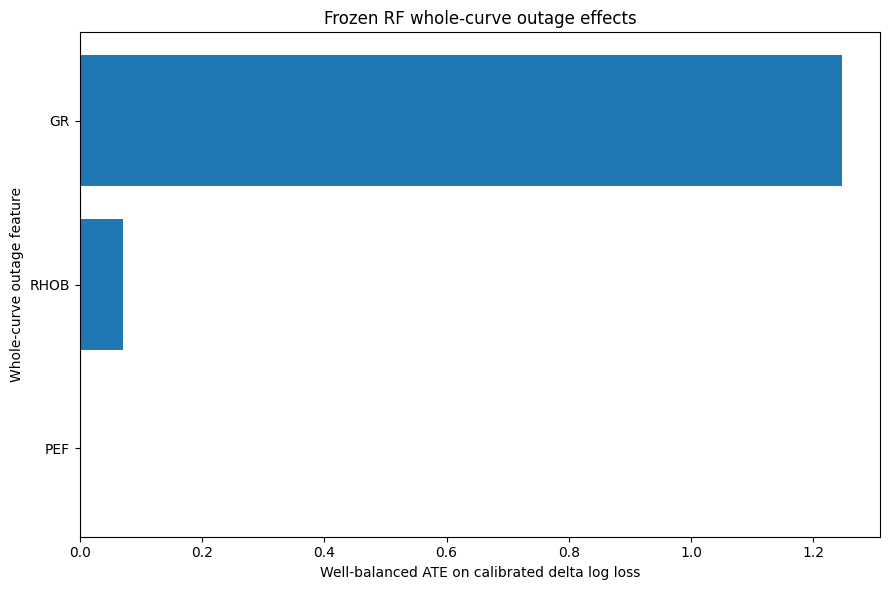

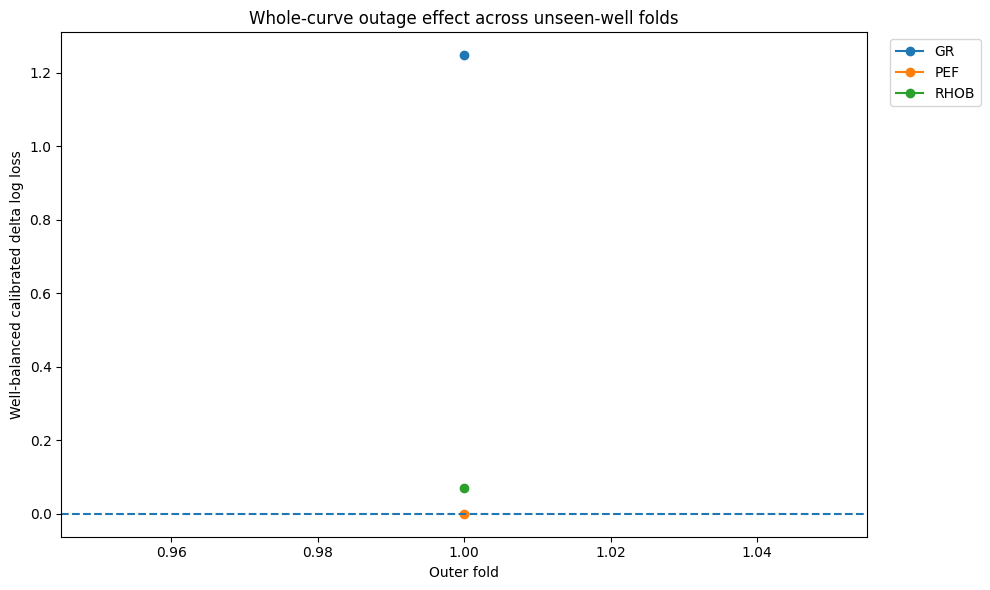

In [17]:
if not feature_ranking_df.empty:
    plot_df = (
        feature_ranking_df
        .sort_values(
            "pooled_well_balanced_ATE_delta_log_loss_calibrated",
            ascending=True,
        )
    )

    plt.figure(
        figsize=(9, 6)
    )

    plt.barh(
        plot_df["feature"],
        plot_df[
            "pooled_well_balanced_ATE_delta_log_loss_calibrated"
        ],
    )

    plt.axvline(
        0.0,
        linestyle="--",
    )

    plt.xlabel(
        "Well-balanced ATE on calibrated delta log loss"
    )

    plt.ylabel(
        "Whole-curve outage feature"
    )

    plt.title(
        "Frozen RF whole-curve outage effects"
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / "01_feature_effect_ranking.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


if not condition_summary_df.empty:
    pivot = (
        condition_summary_df.pivot(
            index="feature",
            columns="outer_fold",
            values=(
                "well_balanced_ATE_delta_log_loss_calibrated"
            ),
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    for feature in pivot.index:
        plt.plot(
            pivot.columns,
            pivot.loc[feature],
            marker="o",
            label=feature,
        )

    plt.axhline(
        0.0,
        linestyle="--",
    )

    plt.xlabel(
        "Outer fold"
    )

    plt.ylabel(
        "Well-balanced calibrated delta log loss"
    )

    plt.title(
        "Whole-curve outage effect across unseen-well folds"
    )

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / "02_fold_effect_stability.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

In [18]:
fold_summary.to_csv(
    OUTPUT_DIR
    / "00_fold_assignment_summary.csv",
    index=False,
)

descendant_map_df.to_csv(
    OUTPUT_DIR
    / "01_model_descendant_map.csv",
    index=False,
)

intervention_registry.to_csv(
    OUTPUT_DIR
    / "02_intervention_registry.csv",
    index=False,
)

baseline_replay_df.to_csv(
    OUTPUT_DIR
    / "03_baseline_replay_audit.csv",
    index=False,
)

no_op_df.to_csv(
    OUTPUT_DIR
    / "04_no_op_negative_control.csv",
    index=False,
)

condition_summary_df.to_csv(
    OUTPUT_DIR
    / "05_fold_feature_condition_summary.csv",
    index=False,
)

all_per_well_df.to_csv(
    OUTPUT_DIR
    / "06_all_per_well_effects.csv",
    index=False,
)

all_per_lithology_df.to_csv(
    OUTPUT_DIR
    / "07_all_per_lithology_CATE.csv",
    index=False,
)

feature_ranking_df.to_csv(
    OUTPUT_DIR
    / "08_feature_effect_ranking.csv",
    index=False,
)

structural_control_df.to_csv(
    OUTPUT_DIR
    / "09_structural_zero_path_controls.csv",
    index=False,
)

execution_manifest_df.to_csv(
    OUTPUT_DIR
    / "10_execution_manifest.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "11_intervention_engine_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        ENGINE_GATE,
        file,
        ensure_ascii=False,
        indent=2,
    )

run_configuration = {
    "stage": (
        "04_frozen_RF_whole_curve_outage"
    ),
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "outer_folds": (
        ACTIVE_OUTER_FOLDS
    ),
    "features": ACTIVE_FEATURES,
    "interventions_executed": [
        "T0_NO_OP",
        "T2_WHOLE_OUTAGE",
    ],
    "treatment_definition": (
        "all originally observed finite values "
        "of the target feature are set to NaN "
        "within the outer validation fold"
    ),
    "primary_outcome": (
        "nested_calibrated_delta_log_loss"
    ),
    "primary_estimand": (
        "well_balanced_ATE"
    ),
    "secondary_outcomes": [
        "raw_delta_log_loss",
        "delta_true_class_probability",
        "prediction_flip",
        "necessity_rate",
        "accuracy_change",
    ],
    "eligibility": (
        "feature originally observed and finite"
    ),
    "random_forest_retrained": False,
    "random_forest_modified": False,
    "scaler_refitted": False,
    "imputer_refitted": False,
    "temperature_refitted": False,
    "descendants_recomputed": True,
    "temperature_source": (
        "03_nested_grouped_temperature_calibration/full"
    ),
    "model_source": (
        "02B_legacy_RF_grouped_well_CV/full/artifacts"
    ),
    "legacy_refined_labels_used_for_primary_outcome": False,
    "row_level_effects_saved": (
        SAVE_ROW_LEVEL_EFFECTS
    ),
    "prediction_batch_size": (
        PREDICTION_BATCH_SIZE
    ),
    "claim_scope": (
        "controlled measurement interventions "
        "on frozen model predictions and errors"
    ),
    "excluded_claim": (
        "well logs physically cause lithology"
    ),
    "next_stage": (
        "local masking on homogeneous 5m, 15m, and 30m windows"
    ),
}

with open(
    OUTPUT_DIR
    / "12_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("All outputs saved in:")
print(OUTPUT_DIR)

All outputs saved in:
${STRATASHIFT_ARTIFACT_ROOT}/04_frozen_RF_whole_curve_outage/pilot
